# 🔍 **Практический разбор EDA (Exploratory Data Analysis)**

**Датасет:** Spotify Tracks Dataset (Kaggle)  
**Бизнес-задача:** «Что делает песню хитом?»  

# Автор: Олег Булыгин

<div style="background-color: #f5f5f5; border-left: 5px solid #3498db; padding: 10px; margin: 10px 0;">

## Обо мне

🐍 **Эксперт по Python и Data Science**. В 2020 году ушёл из найма, сейчас реализую собственные проекты, занимаюсь IT-образованием и консультированием.

👨‍💻 **Опыт в образовании**. В IT-образовании с 2016 года. За это время провел более 1500 лекций и вебинаров, обучил тысячи студентов, многие из которых сейчас работают в ведущих IT-компаниях. Создаю авторские курсы, консультирую крупные компании по вопросам Data Science и участвую в разработке образовательных программ для университетов и онлайн-школ.

🎯 Стремлюсь сделать обучение качественным и честным для всех, кто хочет развиваться в IT-сфере.

📱 Делюсь полезными материалами об IT и AI в:
- [Sponsr](https://sponsr.ru/payload/)
- [Telegram](https://t.me/oleg_payload)
- [Дзен](https://dzen.ru/payload)
</div>


---

## 🎯 **Цели занятия**

На занятии мы будем учиться:
- **Понимать** философию EDA и её место в аналитическом workflow.
- **Оценивать** качество данных: находить пропуски, дубликаты, выбросы.
- **Очищать** данные от аномалий (нулевые значения, треки с нулевой продолжительностью).
- **Анализировать** распределения признаков с помощью гистограмм и boxplot.
- **Исследовать** взаимосвязи между признаками с помощью корреляций (φk).
- **Сегментировать** данные по жанрам и сравнивать профили с помощью radar chart.
- **Формулировать** бизнес-инсайты на основе данных («Что делает песню хитом?»).
- **Автоматизировать** EDA с помощью ydata-profiling.

**Бизнес-кейс:** лейбл звукозаписи хочет понять, какие характеристики треков коррелируют с популярностью, чтобы принимать решения о продвижении артистов на основе данных.

---

## 📚 **Импорты и настройки**

In [ ]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Загрузка данных
import kagglehub

---

# **Часть 1. Философия EDA** 🧠

## **1.1 Что такое EDA**?

**Exploratory Data Analysis (EDA)** — это системный подход к пониманию данных. Включает в себя анализ основных свойств данных, нахождение в них общих закономерностей, распределений и аномалий, построение начальных моделей, зачастую с использованием инструментов визуализации.

### **История**
Концепция EDA разработана американским математиком Джоном Тьюки ещё в 1977 году, и до сих пор является важным этапом аналитических работ.
Он сравнивал анализ данных с работой детектива:
- ищем улики (паттерны),
- допрашиваем свидетелей (данные),
- строим гипотезы (инсайты).




## **1.2 Бизнес-контекст**

### «Что делает песню хитом?»

**Заказчик:** Лейбл звукозаписи  
**Задача:** Понять, какие характеристики треков коррелируют с популярностью  
**Цель:** Принимать решения о продвижении артистов на основе данных

### Датасет Spotify Tracks
- ~114,000 треков
- Audio features: danceability, energy, loudness, tempo, valence, etc.
- Метаданные: artist, genre, popularity
- Источник: Spotify Web API

## **1.3 Загрузка данных**

In [ ]:
# Загрузка датасета с Kaggle
path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
df = pd.read_csv(f"{path}/dataset.csv", index_col=0)

Using Colab cache for faster access to the '-spotify-tracks-dataset' dataset.


 ### 📋 Описание столбцов датасета

| Столбец | Тип | Описание |
|---------|-----|----------|
| **track_id** | str | Уникальный идентификатор трека в Spotify |
| **artists** | str | Имя исполнителя (или нескольких через `;`) |
| **album_name** | str | Название альбома |
| **track_name** | str | Название трека |
| **popularity** | int | Популярность трека (0-100) |
| **duration_ms** | int | Длительность в миллисекундах |
| **explicit** | bool | Наличие нецензурной лексики |
| **danceability** | float | Танцевальность (0-1) |
| **energy** | float | Энергичность (0-1) |
| **key** | int | Тональность (0=C, 1=C#, ..., 11=B) |
| **loudness** | float | Громкость в dB (обычно от -60 до 0) |367 |
| **mode** | int | Мажор (1) или минор (0) |
| **speechiness** | float | Доля речи/вокала (0-1) |
| **acousticness** | float | Акустичность (0-1) |
| **instrumentalness** | float | Инструментальность (0-1) |
| **liveness** | float | «Живость» записи (0-1) |
| **valence** | float | Позитивность настроения (0-1) |
| **tempo** | float | Темп в BPM (ударов в минуту) |
| **time_signature** | int | Размер такта (обычно 4) |
| **track_genre** | str | Жанр трека |


---

# **Часть 2. Первичный осмотр данных** 📀

## **2.1 Первый взгляд на данные**

In [ ]:
# Первые 5 строк
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic



- Какие колонки сразу понятны?
- Какие требуют объяснения?

In [ ]:
# Случайная выборка — всегда смотрите разные срезы!
df.sample(5, random_state=42)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
113186,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,0.598,7,-6.984,1,0.0304,0.00511,0.000000,0.176,0.0466,148.014,4,world-music
42819,2dp5I5MJ8bQQHDoFaNRFtX,Internal Rot,Grieving Birth,Failed Organum,11,93933,False,0.171,0.997,7,-3.586,1,0.1180,0.00521,0.801000,0.420,0.0294,122.223,4,grindcore
59311,5avw06usmFkFrPjX8NxC40,Zhoobin Askarieh;Ali Sasha,Noise A Noise 20.4-1,"Save the Trees, Pt. 1",0,213578,False,0.173,0.803,9,-10.071,0,0.1440,0.61300,0.001910,0.195,0.0887,75.564,3,iranian
91368,75hT0hvlESnDJstem0JgyR,Bryan Adams,All I Want For Christmas Is You,Merry Christmas,0,151387,False,0.683,0.511,6,-5.598,1,0.0279,0.40600,0.000197,0.111,0.5980,109.991,3,rock
61000,4bY2oZGA5Br3pTE1Jd1IfY,Nogizaka46,バレッタ TypeD,月の大きさ,57,236293,False,0.555,0.941,9,-3.294,0,0.0481,0.48400,0.000000,0.266,0.8130,92.487,4,j-idol


## **2.2 Технический паспорт данных**

In [ ]:
# Информация о структуре
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 

### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(9), int64(6), object(5) | OK, но можно оптимизировать |
| **Пропуски** | Есть в `artists`, `album_name`, `track_name` | Нужно исследовать |

## **2.3 Оптимизация памяти**

Теперь, когда данные очищены, можно оптимизировать типы данных для экономии памяти.

In [ ]:
# Замер памяти до оптимизации
memory_before = df.memory_usage(deep=True).sum() / 1024**2
print(f"💾 Память до: {memory_before:.2f} MB")

💾 Память до: 49.66 MB


In [ ]:
# Анализ типов данных
df.dtypes.value_counts()

,count
float64,9
object,5
int64,5
bool,1


In [ ]:
# Числовые типы
# выбрать атоматически
int_cols = df.select_dtypes(include=['int64']).columns
float_cols = df.select_dtypes(include=['float64']).columns

for col in int_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')

for col in float_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='float')

# Категориальные типы (уникальность < 20%)
cat_candidates = ['explicit', 'track_genre', 'artists', 'album_name']
for col in cat_candidates:
    if col in df.columns:
        unique_ratio = df[col].nunique() / len(df)
        if unique_ratio < 0.2:
            df[col] = df[col].astype('category')
            print(f"📦 {col} → category (уникальность: {unique_ratio:.1%})")

# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"\n💾 Память после: {memory_after:.2f} MB")
print(f"📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")

📦 explicit → category (уникальность: 0.0%)
📦 track_genre → category (уникальность: 0.1%)

💾 Память после: 36.29 MB
📉 Экономия: 26.9%


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype   
---  ------            --------------   -----   
 0   track_id          114000 non-null  object  
 1   artists           113999 non-null  object  
 2   album_name        113999 non-null  object  
 3   track_name        113999 non-null  object  
 4   popularity        114000 non-null  int8    
 5   duration_ms       114000 non-null  int32   
 6   explicit          114000 non-null  category
 7   danceability      114000 non-null  float32 
 8   energy            114000 non-null  float32 
 9   key               114000 non-null  int8    
 10  loudness          114000 non-null  float32 
 11  mode              114000 non-null  int8    
 12  speechiness       114000 non-null  float32 
 13  acousticness      114000 non-null  float32 
 14  instrumentalness  114000 non-null  float32 
 15  liveness          114000 non-null  float32 
 16  valence

## **2.4 Статистическая сводка**

In [ ]:
# Числовые переменные
df.describe().T

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.000000,17.000000,35.000000,50.000000,1.000000e+02
duration_ms,114000.0,228029.153114,107297.712645,0.000000,174066.000000,212906.000000,261506.000000,5.237295e+06
danceability,114000.0,0.566800,0.173539,0.000000,0.456000,0.580000,0.695000,9.850000e-01
energy,114000.0,0.641383,0.251529,0.000000,0.472000,0.685000,0.854000,1.000000e+00
key,114000.0,5.309140,3.559987,0.000000,2.000000,5.000000,8.000000,1.100000e+01
loudness,114000.0,-8.258961,5.029269,-49.530998,-10.013000,-7.004000,-5.003000,4.532000e+00
mode,114000.0,0.637553,0.480709,0.000000,0.000000,1.000000,1.000000,1.000000e+00
speechiness,114000.0,0.084652,0.105732,0.000000,0.035900,0.048900,0.084500,9.650000e-01
acousticness,114000.0,0.314910,0.332522,0.000000,0.016900,0.169000,0.598000,9.960000e-01
instrumentalness,114000.0,0.156050,0.309615,0.000000,0.000000,0.000042,0.049000,1.000000e+00


In [ ]:
# Категориальные переменные
df.describe(include=['object', 'category']).T

,count,unique,top,freq
track_id,114000,89741,6S3JlDAGk3uu3NtZbPnuhS,9
artists,113999,31437,The Beatles,279
album_name,113999,46589,Alternative Christmas 2022,195
track_name,113999,73608,Run Rudolph Run,151
explicit,114000,2,False,104253
track_genre,114000,114,acoustic,1000


---

# **Часть 3. Качество данных** 🧹

## **3.1 Анализ пропусков**

In [ ]:
# Количество пропусков
missing_count = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print("📊 Пропуски в данных:")
missing_df

📊 Пропуски в данных:


,Пропуски,%
artists,1,0.0
album_name,1,0.0
track_name,1,0.0


### **Вывод:** всего 1 строка с пропусками.
Не заморачиваемся, удаляем.


In [ ]:
df = df.dropna()

## **3.2 Анализ выбросов**

### **Визуальный метод: boxplot**

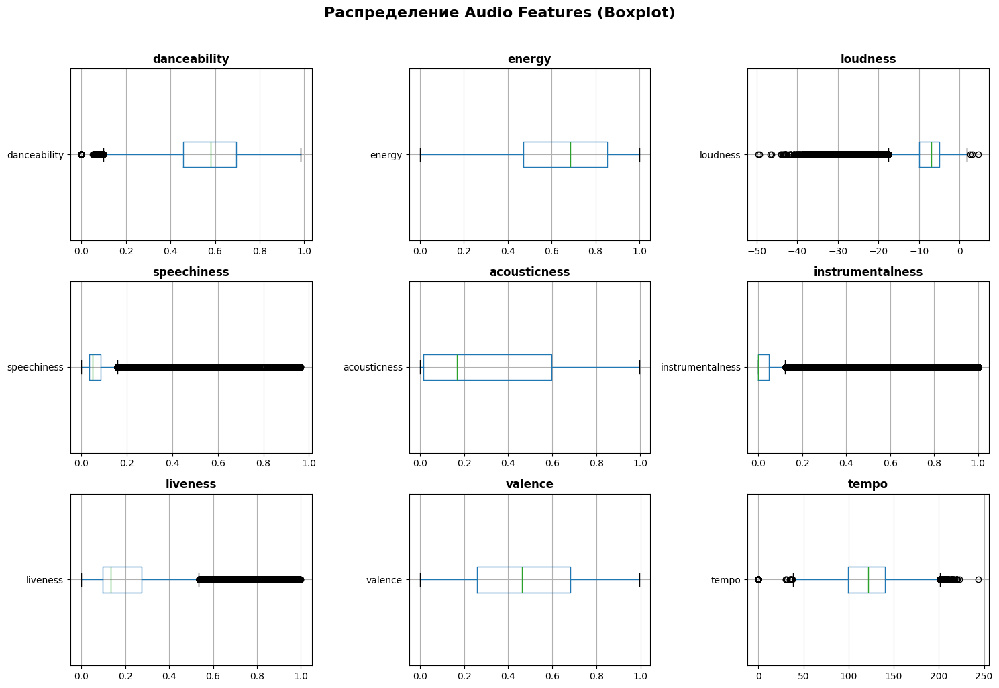

In [ ]:
# Audio features для анализа выбросов
audio_features = ['danceability', 'energy', 'loudness', 'speechiness',
                  'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

# Boxplot для всех audio features
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, col in enumerate(audio_features):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение Audio Features (Boxplot)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 🔍 **Анализ выбросов:**

| Признак | Выбросы | Интерпретация |
|---------|---------|---------------|
| **loudness** | Много < -20 dB | Очень тихие треки (возможно классика) |
| **speechiness** | Много > 0.5 | Подкасты, аудиокниги, рэп |
| **instrumentalness** | Много > 0.5 | Инструментальная музыка |
| **liveness** | Много > 0.5 | Концертные записи |
| **tempo** | Есть = 0 | Специфичные объекты (вероятно, не музыка) |

### **Проверка аномалий**

In [ ]:
# Tempo = 0 — что это?
zero_tempo = df[df['tempo'] == 0]
print(f"🎵 Треков с tempo = 0: {len(zero_tempo)}")

if len(zero_tempo) > 0:
    print("\nПримеры:")
    display(zero_tempo)

🎵 Треков с tempo = 0: 157

Примеры:


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
4131,59gg6zQhSKGVnkT3hWAY3l,Max Richter;Lang Lang,Voyager - Essential Max Richter,The Departure,64,151506,False,0.0,0.03620,0,-22.518999,0,0.0,0.994000,0.940,0.0958,0.0,0.0,0,ambient
4379,4acmzQsAeMJa5sGFSog7fu,Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,Jane Eyre - Original Motion Picture Soundtrack,The End of Childhood (feat. Jack Liebeck),55,73266,False,0.0,0.04450,0,-26.440001,0,0.0,0.972000,0.972,0.0873,0.0,0.0,0,ambient
4664,1Kb2DqjHRvOcT5xeWtz3t5,Sylvain Chauveau,Des Plumes Dans La Tête,Ferme Les Yeux,53,68493,False,0.0,0.03230,2,-23.636000,0,0.0,0.994000,0.973,0.0922,0.0,0.0,0,ambient
45670,6B9Mgf9smWqxDjA35VD6MK,Little Symphony,Rialto Beach,Campomoro,22,148711,False,0.0,0.00108,0,-30.204000,1,0.0,0.952000,0.991,0.2420,0.0,0.0,0,guitar
45720,7i5OoyPXtSrqz9jobJfG1F,Little Symphony,Rialto Beach,Ritornello,23,102000,False,0.0,0.00129,7,-29.445000,1,0.0,0.969000,0.956,0.1230,0.0,0.0,0,guitar
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101988,5gEKRH0MCSegG8ZISUPaU2,Granular,The World Of,Tin White Noise,32,182050,False,0.0,0.00002,1,-16.187000,1,0.0,0.003850,0.903,0.9210,0.0,0.0,0,sleep
101993,6H0kAiSAFB84jX7dgEDWd6,Rain Sounds,Rain,Rain: Natural Recording,32,84219,False,0.0,0.02540,8,-19.924999,1,0.0,0.000002,0.838,0.3390,0.0,0.0,0,sleep
113428,5EYzrykQ95uOmepteDi9KT,El Ruido Blanco;Soñoliento Juan;Mantra para Do...,Aire Acondicionado de Ruido Blanco,Aire de verano,27,128000,False,0.0,0.18800,8,-25.837000,0,0.0,0.139000,0.339,0.1220,0.0,0.0,0,world-music
113688,2EnZf7wbFv7ST4CJ3EvNzT,El Ruido Blanco,Ruido Blanco para el bebé: sonidos relajantes ...,Ruido Rosa Puro - Una Hora Versión,24,3601693,False,0.0,0.00002,1,-11.165000,1,0.0,0.186000,1.000,0.3620,0.0,0.0,0,world-music



**Наш выбор: удаление**  
Количество треков с tempo=0 минимально

In [ ]:
df[df['track_genre'] == 'sleep']

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
101000,07UDTaRYJAsIhUZTyZSUzM,Huma,Ons,Ons,71,193239,False,0.1110,0.018500,0,-32.334999,1,0.0424,0.95700,0.940,0.087,0.04590,76.153000,3,sleep
101001,0CMYUXTTTmI6Lwc0opH2XG,Sohn Aelia,Herinneringen,Herinneringen,74,172357,False,0.0685,0.003420,0,-37.155998,1,0.0418,0.99000,0.910,0.106,0.05810,73.643997,1,sleep
101002,5LEHlRPjGcZ5RdagAwXpHS,Little Circuits,Beautiful Imagination,Beautiful Imagination,71,143052,False,0.1020,0.033300,3,-34.176998,1,0.0476,0.79700,0.927,0.111,0.05910,89.605003,4,sleep
101003,58xXb7ASilQ9WYtninubrY,White Noise for Babies,Thinned Phaser,Aqua,0,157024,False,0.2400,0.011900,6,-33.514999,0,0.0760,0.99500,0.828,0.103,0.03580,138.009003,4,sleep
101004,6kOJ0Ylenwr6Up0g4lDORg,White Noise for Babies,Rising Sun,Rising Sun,0,180000,False,0.1350,0.000804,4,-34.771999,1,0.0507,0.96800,0.728,0.108,0.03460,141.929993,5,sleep
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101995,0j8vIJU0isc5Jhrl1sfjd5,Rain Sounds,Soft Rain Sleep,Carribean Rain,32,74649,False,0.1790,0.581000,5,-22.416000,0,0.0702,0.00626,0.657,0.581,0.03820,83.018997,4,sleep
101996,3OwZ8e7lb5Assv14ZRW1rU,Rain Sounds,Soft Rain Sleep,Forrest Rain,32,102649,False,0.4680,0.993000,10,-24.274000,0,0.0386,0.25000,0.945,0.932,0.00964,49.296001,4,sleep
101997,3QZrgBLusdGcYJtST0ucXX,Rain Sounds,White Noise Rain,White Noise Rain,32,173608,False,0.1740,0.895000,2,-24.459000,1,0.0468,0.17200,0.919,0.875,0.00001,86.751999,5,sleep
101998,6hD4qRIXuuD2cM7vX6eV23,Meeresrauschen,"Meeresrauschen zur Entspannung, für Meditation...",Relax,32,120353,False,0.1880,0.999000,10,-18.900000,1,0.0510,0.47400,0.988,0.929,0.00001,60.837002,3,sleep


In [ ]:
df_clean = df[df['track_genre'] != 'sleep']
df_clean

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746000,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917000,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235001,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.488998,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734000,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332001,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.514999,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740005,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681000,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.948997,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,5,-16.393000,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995003,5,world-music
113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,0,-18.318001,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.238998,4,world-music
113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,0,-10.895000,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378006,4,world-music
113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,7,-10.889000,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960007,4,world-music


In [ ]:
# Удаление треков с tempo = 0 из df_clean
df_clean = df_clean[df_clean['tempo'] > 0]
print(f"📊 Размер df_clean: {len(df_clean):,} строк")

📊 Размер df_clean: 112,980 строк


### Проверка треков с нулевой продолжительностью

In [ ]:
# Проверка duration_ms
print(f"\n🎵 Треков с duration_ms = 0: {len(df_clean[df_clean['duration_ms'] == 0])}")
print(f"🎵 Треков с duration_ms < 1000 (менее 1 сек): {len(df_clean[df_clean['duration_ms'] < 1000])}")

# Примеры треков с нулевой продолжительностью
if len(df_clean[df_clean['duration_ms'] == 0]) > 0:
    print("\nПримеры треков с duration_ms = 0:")
    display(df_clean[df_clean['duration_ms'] == 0][['track_name', 'artists', 'duration_ms', 'popularity']].head())

# Удаление нулевых треков
df_clean = df_clean[df_clean['duration_ms'] > 0].copy()
print(f"\n✅ Удалено треков с duration_ms = 0")
print(f"📊 Размер df_clean: {len(df_clean):,} строк")


🎵 Треков с duration_ms = 0: 0
🎵 Треков с duration_ms < 1000 (менее 1 сек): 0

✅ Удалено треков с duration_ms = 0
📊 Размер df_clean: 112,980 строк


### 🔍 **Проверка нулевых значений во всех audio features**

In [ ]:
print("\n🔍 Проверка нулевых значений в audio features:")
for col in audio_features:
    zero_count = len(df_clean[df_clean[col] == 0])
    if zero_count > 0:
        print(f"  {col}: {zero_count} треков с значением 0")


🔍 Проверка нулевых значений в audio features:
  acousticness: 19 треков с значением 0
  instrumentalness: 38716 треков с значением 0
  valence: 7 треков с значением 0


## **3.3 Анализ дубликатов**

In [ ]:
# Полные дубликаты
full_duplicates = df_clean.duplicated().sum()
print(f"🔁 Полных дубликатов: {full_duplicates:,} ({full_duplicates/len(df)*100:.2f}%)")

🔁 Полных дубликатов: 450 (0.39%)


In [ ]:
# Дубликаты по track_id
track_duplicates = df_clean.duplicated(subset=['track_id']).sum()
print(f"🎵 Дубликатов track_id: {track_duplicates:,} ({track_duplicates/len(df)*100:.2f}%)")

🎵 Дубликатов track_id: 24,256 (21.28%)


### **Почему track_id дублируется?**
Один трек может быть в нескольких жанрах!

In [ ]:
# Пример дубликата track_id
duplicate_ids = df_clean[df_clean.duplicated(subset=['track_id'], keep=False)]['track_id'].value_counts().head(3)
print("🔝 Топ-3 track_id по количеству повторов:")
print(duplicate_ids)

# Смотрим пример
example_id = duplicate_ids.index[0]
df_clean[df_clean['track_id'] == example_id]

🔝 Топ-3 track_id по количеству повторов:
track_id
6S3JlDAGk3uu3NtZbPnuhS    9
2Ey6v4Sekh3Z0RUSISRosD    8
2kkvB3RNRzwjFdGhaUA0tz    8
Name: count, dtype: int64


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
8315,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,blues
19759,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,country
34728,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,folk
62226,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,j-pop
63087,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,j-rock
82064,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,power-pop
84129,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,psych-rock
99727,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,singer-songwriter
102732,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,11,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,songwriter


### **Решение по дубликатам:**
- **Полные дубликаты** → удалить.
- **Дубликаты track_id** → требуют агрегации для корректного анализа.

In [ ]:
# Удаление полных дубликатов
df_clean = df_clean.drop_duplicates()
print(f"✅ Удалено полных дубликатов: {len(df) - len(df_clean):,}")
print(f"📊 Размер после очистки: {len(df_clean):,} строк")

✅ Удалено полных дубликатов: 1,469
📊 Размер после очистки: 112,530 строк




Теперь, когда удалили все проблемные записи, создаём финальный датасет с уникальными треками.

In [ ]:
df_unique = df_clean.groupby('track_id').first().reset_index()


print(f"📊 Уникальных треков: {len(df_unique):,}")
print(f"📉 Исходный размер: {len(df_clean):,}")
print(f"🔄 Разница: {len(df_clean) - len(df_unique):,} записей ({(len(df_clean) - len(df_unique))/len(df_clean)*100:.1f}%)")

📊 Уникальных треков: 88,724
📉 Исходный размер: 112,530
🔄 Разница: 23,806 записей (21.2%)




### **Какой датасет использовать?**
- **df_unique** - для анализа распределений, корреляций, сравнения хитов (один трек = одна запись)
- **df_clean** - для анализа жанров (один трек может быть в нескольких жанрах)

---

# **Часть 4. Одномерный анализ** 📊

## **4.1 Распределение популярности (целевая переменная)**

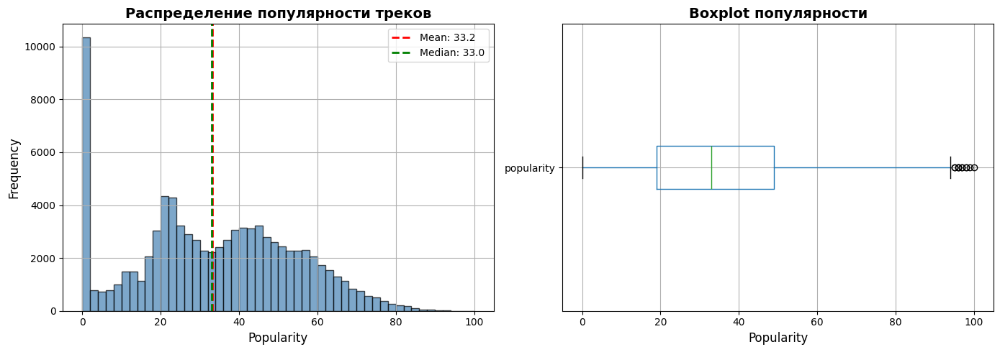

In [ ]:
# Гистограмма популярности
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
ax1 = axes[0]
df_unique['popularity'].hist(bins=50, ax=ax1, color='steelblue', edgecolor='black', alpha=0.7)
ax1.axvline(df_unique['popularity'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_unique["popularity"].mean():.1f}')
ax1.axvline(df_unique['popularity'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df_unique["popularity"].median():.1f}')
ax1.set_xlabel('Popularity', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('Распределение популярности треков', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)

# KDE + Boxplot
ax2 = axes[1]
df_unique.boxplot(column='popularity', ax=ax2, vert=False)
ax2.set_title('Boxplot популярности', fontsize=14, fontweight='bold')
ax2.set_xlabel('Popularity', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# Анализ треков с popularity = 0
zero_popularity = df_unique[df_unique['popularity'] == 0]
print(f"🎵 Треков с popularity = 0: {len(zero_popularity)}")
if len(zero_popularity) > 0:
    print("\nПримеры треков с popularity = 0:")
    display(zero_popularity[['track_name', 'album_name', 'artists', 'popularity', 'track_genre']])

## **4.2 Распределение Audio Features**

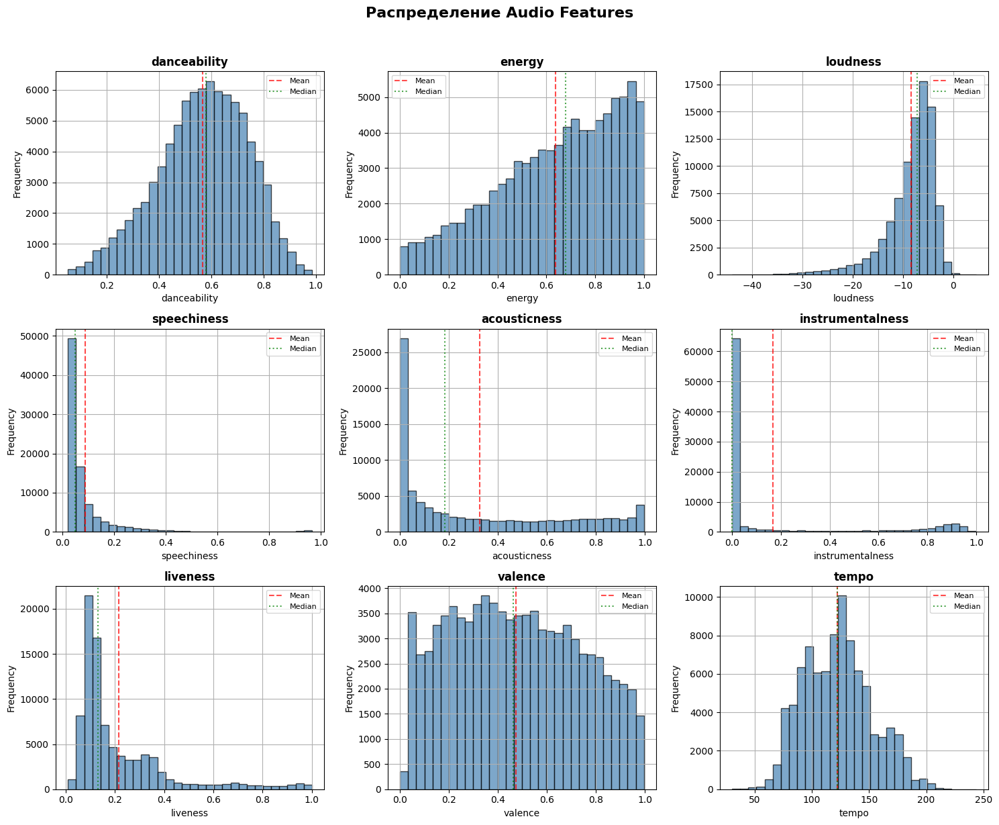

In [ ]:
# Гистограммы всех audio features
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for idx, col in enumerate(audio_features):
    ax = axes[idx]
    df_unique[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)

    # Добавляем линии mean и median
    ax.axvline(df_unique[col].mean(), color='red', linestyle='--', alpha=0.7, label='Mean')
    ax.axvline(df_unique[col].median(), color='green', linestyle=':', alpha=0.7, label='Median')
    ax.legend(fontsize=8)

plt.suptitle('Распределение Audio Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
df_unique[df_unique['acousticness'] == 0]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
1698,09NHX3DzPqHN2m05LifEiP,Hypocrisy,Abducted,Paradox,18,272453,False,0.0749,0.824,11,-7.492,0,0.0880,0.0,0.855,0.1060,0.3220,80.231003,4,black-metal
3071,0GxyutETmsiOx8k0bDpq27,Windir,Likferd,Martyrium,21,300226,False,0.2530,0.865,8,-5.575,1,0.0558,0.0,0.924,0.1170,0.1600,88.005997,3,black-metal
3658,0K5qXGfXQVOn3PrRsRxNAo,Nasum,Human 2.0,Multinational Murderers Network,11,138626,False,0.2190,0.978,9,-6.503,1,0.1480,0.0,0.929,0.0811,0.0755,112.711998,4,grindcore
4042,0MNMTMcvctrTAjf1I378ra,Full Of Hell,Full of Hell & Merzbow,Mute,17,33286,False,0.2000,0.472,6,-3.390,1,0.2280,0.0,0.638,0.8280,0.0000,56.228001,4,grindcore
19124,1fzfivd2zAPbSgfxVPpC9m,Tsjuder,Desert Northern Hell,Lord of Swords,18,256200,False,0.2010,0.973,9,-6.173,0,0.0984,0.0,0.849,0.0803,0.1950,112.121002,4,black-metal
23547,24EgYQxyTKvNbFhvT8VsNt,Regurgitate,Carnivorous Erection,Copious Head Carnage,11,63093,False,0.2460,0.991,1,-6.861,0,0.1750,0.0,0.923,0.1130,0.0847,111.704002,4,grindcore
30365,2fJ448Aj8oYxHKILgqr6Bx,Ninkharsag,Blood Of Celestial Kings,The Sicarii,17,222880,False,0.1720,0.951,6,-5.129,0,0.0992,0.0,0.886,0.1150,0.1970,122.019997,4,black-metal
57262,52KUWZO1AdRXIaIaKZor0R,Hypocrisy,Abducted,Abducted,19,170546,False,0.1750,0.950,7,-7.358,1,0.1210,0.0,0.846,0.3220,0.1250,119.416000,4,black-metal
57520,53pgPzvcfZOJzj3g7ozoD8,Disfear,Misanthropic Generation,Misanthropic Generation,15,254000,True,0.1260,0.989,5,-5.089,1,0.1080,0.0,0.817,0.1230,0.1630,148.658005,4,grindcore
62586,5VPS2mSgfIyp7Y45WRcV8w,Hypocrisy,Abducted,Buried,18,191226,True,0.2220,0.986,2,-9.135,1,0.0822,0.0,0.828,0.1530,0.0545,154.425995,4,black-metal


## **4.3 Анализ жанров**

In [ ]:
# Проверка сбалансированности жанров
genre_counts = df_clean['track_genre'].value_counts()
print(f"📊 Количество уникальных жанров: {len(genre_counts)}")
print(f"\n📈 Статистика по количеству треков в жанре:")
print(f"   Min: {genre_counts.min()}")
print(f"   Max: {genre_counts.max()}")
print(f"   Mean: {genre_counts.mean():.0f}")
print(f"   Std: {genre_counts.std():.0f}")

📊 Количество уникальных жанров: 114

📈 Статистика по количеству треков в жанре:
   Min: 0
   Max: 1000
   Mean: 987
   Std: 94


In [ ]:
genre_counts

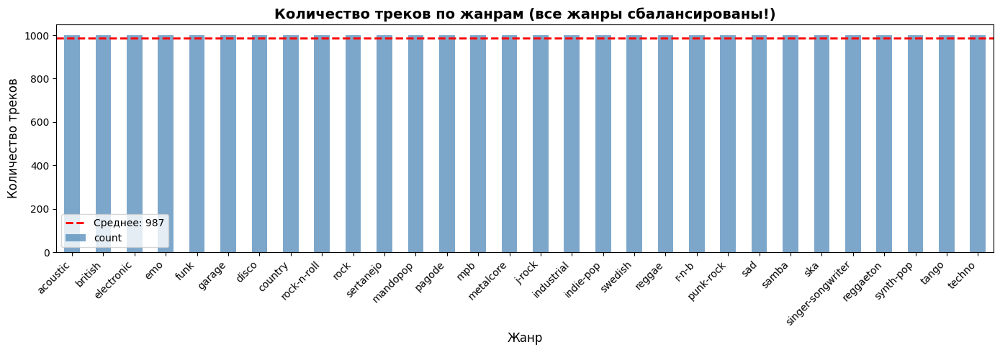

In [ ]:
# Визуализация сбалансированности
fig, ax = plt.subplots(figsize=(14, 5))
genre_counts.head(30).plot(kind='bar', ax=ax, color='steelblue', alpha=0.7)
ax.axhline(genre_counts.mean(), color='red', linestyle='--', linewidth=2,
           label=f'Среднее: {genre_counts.mean():.0f}')
ax.set_xlabel('Жанр', fontsize=12)
ax.set_ylabel('Количество треков', fontsize=12)
ax.set_title('Количество треков по жанрам (все жанры сбалансированы!)', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 🔍 **Важное наблюдение:** жанры сбалансированы!

В датасете все жанры представлены примерно одинаковым количеством треков (~1000).
Это означает, что **value_counts() не показывает популярность жанров** —
он показывает только структуру датасета!

| Заблуждение | Реальность |
|-------------|------------|
| "Жанр A популярнее, потому что его больше" | Нет, это просто структура датасета |
| value_counts() показывает популярность | Нет, это количество записей |

**Как тогда анализировать популярность жанров?**
→ Смотреть среднюю популярность треков внутри жанра

---

# **Часть 5. Многомерный анализ** 🔗

## **5.1 Визуальный анализ взаимосвязей (pairplot)**

**Принцип EDA:** Сначала смотрим, потом считаем!
Pairplot позволяет визуально оценить взаимосвязи до расчёта корреляций.

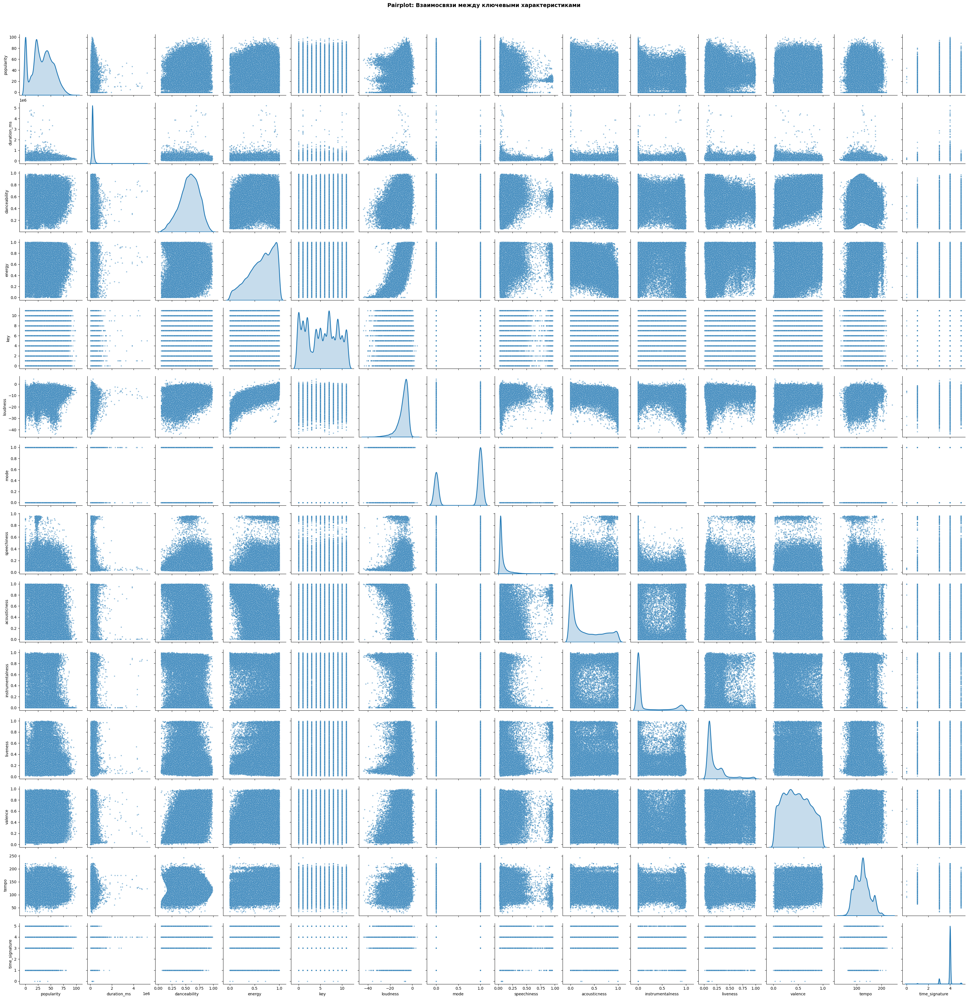

In [ ]:
# Pairplot
sns.pairplot(df_unique, diag_kind='kde',
             plot_kws={'alpha': 0.5, 's': 10},
             diag_kws={'linewidth': 2})
plt.suptitle('Pairplot: Взаимосвязи между ключевыми характеристиками',
             fontsize=14, fontweight='bold', y=1.02)
plt.show()

**5.2 Корреляционный анализ с φk (phik)**

### Почему не Пирсон?

**Коэффициент Пирсона** имеет ограничения:
- Работает только для линейных зависимостей
- Требует непрерывные переменные
- Чувствителен к выбросам

**φk (phi-k) коэффициент** — универсальная альтернатива:
- ✅ Работает с любыми типами переменных (числовые, категориальные)
- ✅ Улавливает нелинейные связи
- ✅ Устойчив к выбросам

In [ ]:
# Импорт библиотеки phik
!pip install phik
import phik
from phik import resources, report

### **Матрица корреляций φk**

**Важно:** для корректного расчёта φk нужно явно указать интервальные (непрерывные) переменные через параметр `interval_cols`. Это позволяет библиотеке правильно определить типы переменных и выбрать соответствующий метод расчёта корреляции.

In [ ]:
# Определяем интервальные (непрерывные) переменные
interval_cols = ['popularity', 'duration_ms', 'danceability', 'energy', 'key',
                 'loudness', 'speechiness', 'acousticness', 'instrumentalness',
                 'liveness', 'valence', 'tempo', 'time_signature']

# Расчёт матрицы phik с явным указанием интервальных переменных
phik_matrix = df_unique.drop(['artists', 'track_id', 'track_name', 'album_name', 'track_genre'],
                      axis=1).phik_matrix(interval_cols=interval_cols)

# Heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица корреляций φk (phik)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 💡 **Ключевой инсайт:**
**Нет одной «волшебной» характеристики, которая делает трек популярным!**
Популярность — это сложная комбинация факторов + маркетинг + удача.

---

# **Часть 6. Сегментированный анализ** 🎵

## **6.1 Профили жанров через Radar Chart**

Теперь проанализируем, как жанры различаются по своим audio features.

**Стратегия:**
1. Выберем топ-5 жанров по медианной популярности (5 — оптимально для визуального сравнения)
2. Используем визуализации, которые показывают **профиль жанра** целиком

In [ ]:
# Определяем топ-5 жанров по средней популярности
top_genres_by_popularity = (df_clean[df_clean['popularity'] != 0].groupby('track_genre')['popularity']
                               .median()
                               .sort_values(ascending=False)
                               .head(5))

print("🔝 Топ-5 жанров по средней популярности:")
print(top_genres_by_popularity.round(1))

In [ ]:
# Ключевые audio features для сравнения (все в диапазоне 0-1)
features_for_comparison = ['danceability', 'energy', 'speechiness',
                           'acousticness', 'instrumentalness', 'valence', 'liveness']

selected_genres = top_genres_by_popularity.index.tolist()

# Расчёт средних значений по жанрам
genre_stats = (df_clean[df_clean['track_genre'].isin(selected_genres)]
               .groupby('track_genre')[features_for_comparison]
               .median())



**Radar Chart** — идеальный инструмент для сравнения многомерных профилей.
Каждый жанр представлен как «паутина», где:
- Оси — audio features.
- Расстояние от центра — среднее значение.
- Форма «паутины» — уникальный профиль жанра.

In [ ]:
# =============================================================================
# RADAR CHART: Профили жанров
# =============================================================================
# Подготовка данных для radar chart
categories = features_for_comparison
N = len(categories)

# Создаём углы для каждой оси
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Замыкаем круг

# Цвета для жанров
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']

# Создаём фигуру
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Рисуем каждый жанр
for idx, genre in enumerate(selected_genres):
    values = genre_stats.loc[genre].values.flatten().tolist()
    values += values[:1]  # Замыкаем линию

    ax.plot(angles, values, 'o-', linewidth=2, label=genre, color=colors[idx])
    ax.fill(angles, values, alpha=0.15, color=colors[idx])

# Настройка осей
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

# Легенда и заголовок
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)
ax.set_title('Профили Audio Features по жанрам\n(топ-5 по популярности)',
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

### 🔍 **Как читать Radar Chart:**

| Элемент | Интерпретация |
|---------|---------------|
| **Форма "паутины"** | Уникальный профиль жанра |
| **Выступы наружу** | Высокие значения признака |
| **Впадины к центру** | Низкие значения признака |
| **Пересечения линий** | Различия между жанрами |


---

## **6.2. «Что делает хит?»** 🎯

In [ ]:
# Критерий хита: popularity > 75 (топ-25%)
hit_threshold = 75

df_unique['is_hit'] = (df_unique['popularity'] >= hit_threshold).astype(int)

print(f"🎯 Порог хита: popularity >= {hit_threshold}")
print(f"\n📊 Распределение:")
print(df_unique['is_hit'].value_counts())
print(f"\nДоля хитов: {df_unique['is_hit'].median()*100:.1f}%")

## **6.3 Сравнение хитов vs обычных треков**

In [ ]:
# Группировка по is_hit
hit_comparison = df_unique[df_unique['popularity'] > 0].groupby('is_hit')[audio_features].median().T
hit_comparison.columns = ['Обычные треки', 'Хиты']
hit_comparison['Разница'] = hit_comparison['Хиты'] - hit_comparison['Обычные треки']
hit_comparison['Разница %'] = ((hit_comparison['Хиты'] / hit_comparison['Обычные треки'] - 1) * 100).round(1)
hit_comparison

### 🎨 **Radar Chart «Профиль хита»**



In [ ]:
# =============================================================================
# RADAR CHART: Хиты vs Обычные треки
# =============================================================================
# Выбираем признаки в диапазоне 0-1 для корректного масштаба
radar_features = ['danceability', 'energy', 'speechiness',
                  'acousticness', 'instrumentalness', 'valence', 'liveness']

# Расчёт медиан для хитов и обычных треков
hit_stats = df_unique[df_unique['popularity'] > 0].groupby('is_hit')[radar_features].median()

# Подготовка данных для radar chart
categories = radar_features
N = len(categories)

# Создаём углы для каждой оси
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Замыкаем круг

# Значения для хитов (is_hit=1) и обычных треков (is_hit=0)
values_hit = hit_stats.loc[1].values.flatten().tolist()
values_hit += values_hit[:1]

values_normal = hit_stats.loc[0].values.flatten().tolist()
values_normal += values_normal[:1]

# Создаём фигуру
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Рисуем хиты (красный)
ax.plot(angles, values_hit, 'o-', linewidth=3, label='🎵 Хиты', color='#FF6B6B')
ax.fill(angles, values_hit, alpha=0.25, color='#FF6B6B')

# Рисуем обычные треки (серый)
ax.plot(angles, values_normal, 'o-', linewidth=3, label='Обычные треки', color='#95A5A6')
ax.fill(angles, values_normal, alpha=0.15, color='#95A5A6')

# Настройка осей
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

# Легенда и заголовок
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=12)
ax.set_title('Профиль хита vs Обычные треки\n(Наглядная разница в audio features)',
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

---

# **Часть 7. Автоматизация EDA с ydata-profiling** 🚀

## **7.1 Что такое ydata-profiling?**

**ydata-profiling** (бывший pandas-profiling) — автоматический генератор EDA-отчётов.

### **Преимущества:**
- ✅ Экономит часы ручной работы.
- ✅ Стандартизированный отчёт.
- ✅ Интерактивные визуализации.
- ✅ Автоматические предупреждения о проблемах.

### **Ограничения:**
- ❌ Не заменяет глубокий анализ.
- ❌ Медленно работает на >100K строк.
- ❌ Не учитывает бизнес-контекст.

In [ ]:
# Автоматический EDA
!pip install ydata-profiling

from ydata_profiling import ProfileReport

## **7.2 Базовое использование**

In [ ]:
# Генерация отчёта (это может занять 1-2 минуты)

profile = ProfileReport(
    df_unique,
    title="Spotify Tracks EDA Report",
    explorative=True,
    correlations={
    "auto": {"calculate": False},
    "phi_k": {"calculate": True}
    }
)
profile




In [ ]:
# Сохранение в HTML
profile.to_file("spotify_eda_report.html")

**ydata-profiling — это инструмент для экономии времени, но не замена пониманию данных!**

---

# **Часть 8. Интерактивный дашборд с Streamlit** 📱


### **Что мы построим:**
- 📊 Dashboard с основными метриками
- 🎛️ Фильтры по жанрам и популярности
- 📈 Интерактивные графики
- 🔍 Таблица с данными

## Код Streamlit-приложения

In [ ]:
"""
🎵 Spotify EDA Dashboard

Интерактивный дашборд для анализа данных Spotify Tracks Dataset.
Запуск: streamlit run spotify_dashboard.py
"""
# import streamlit as st
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# import kagglehub

# st.set_page_config(
#     page_title="Spotify EDA",
#     page_icon="🎵",
#     layout="wide"
# )

# @st.cache_data
# def load_data():
#     path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
#     df = pd.read_csv(f"{path}/dataset.csv", index_col=0)
#     df = df.dropna()
#     df = df.drop_duplicates()
#     df = df[df['tempo'] > 0]
#     df = df[df['duration_ms'] > 0]
#     df = df.groupby('track_id').first().reset_index()
#     return df

# st.title("🎵 Spotify EDA Dashboard")
# st.markdown("**Исследовательский анализ данных Spotify Tracks Dataset**")

# df = load_data()

# st.sidebar.header("📊 Фильтры")

# all_genres = sorted(df['track_genre'].unique())
# selected_genres = st.sidebar.multiselect(
#     "Выберите жанры",
#     options=all_genres,
#     default=['pop', 'rock', 'hip-hop', 'electronic', 'jazz']
# )

# popularity_range = st.sidebar.slider(
#     "Диапазон популярности",
#     min_value=0,
#     max_value=100,
#     value=(0, 100)
# )

# df_filtered = df[
#     (df['track_genre'].isin(selected_genres)) &
#     (df['popularity'] >= popularity_range[0]) &
#     (df['popularity'] <= popularity_range[1])
# ]

# col1, col2, col3 = st.columns(3)
# with col1:
#     st.metric("Всего треков", len(df_filtered))
# with col2:
#     st.metric("Уникальных жанров", df_filtered['track_genre'].nunique())
# with col3:
#     st.metric("Средняя популярность", f"{df_filtered['popularity'].mean():.1f}")

# st.divider()

# tab1, tab2, tab3 = st.tabs(["📈 Распределения", "🔗 Корреляции", "📋 Данные"])

# with tab1:
#     fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#     df_filtered['popularity'].hist(bins=30, ax=axes[0], color='steelblue', edgecolor='black')
#     axes[0].set_xlabel('Popularity')
#     axes[0].set_ylabel('Frequency')
#     axes[0].set_title('Распределение популярности')

#     df_filtered.boxplot(column='popularity', ax=axes[1], vert=False)
#     axes[1].set_title('Boxplot популярности')

#     plt.tight_layout()
#     st.pyplot(fig)

# with tab2:
#     numeric_cols = ['popularity', 'danceability', 'energy', 'loudness', 'valence', 'tempo']
#     corr_matrix = df_filtered[numeric_cols].corr()

#     fig, ax = plt.subplots(figsize=(8, 6))
#     sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
#     ax.set_title('Матрица корреляций')
#     plt.tight_layout()
#     st.pyplot(fig)

# with tab3:
#     st.dataframe(df_filtered[['track_name', 'artists', 'track_genre', 'popularity',
#                               'danceability', 'energy', 'tempo']].head(100))



---

# 📝 **Итоги занятия**

### 1. EDA — это не про код, а про мышление.
> Системный подход к пониманию данных: ищем паттерны → формируем гипотезы → проверяем интуицию.

### 2. Качество данных определяет качество анализа.
| Этап | Что проверяем | Инструменты |
|------|---------------|------------|
| **Полнота** | Пропуски, нулевые значения | `.isna()`, `.dropna()` |
| **Уникальность** | Дубликаты | `.duplicated()`, `.drop_duplicates()` |
| **Корректность** | Выбросы, аномалии | `boxplot`, `.describe()` |
| **Согласованность** | Данные в допустимых диапазонах | Фильтрация по условию |

### 3. Визуализация — первый шаг к инсайту.
> Всегда сначала **смотрим** (гистограммы, boxplot, pairplot), потом **считаем** (корреляции).

### 4. Нет «волшебной» формулы в реальных данных.
> Популярность (или любой целевой показатель) — это **комбинация множества факторов**. Один признак редко объясняет всё.

### 5. Контекст определяет интерпретацию.
> `value_counts()` показывает структуру датасета, а не реальное распределение. Всегда спрашивайте: **«Что этот график говорит о реальном мире, а не о данных?»**